### Load Data

In [231]:
#Load data
import pandas as pd
import numpy as np
import seaborn as sns

liver_data = pd.read_csv('../NCDB_2022/liver.csv')
liver_data.shape

/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_71320/3896725045.py:6: DtypeWarning: Columns (164,170,173,176,177,179,218,219,220,319,320,322,323,331,332,333,334) have mixed types. Specify dtype option on import or set low_memory=False.
  liver_data = pd.read_csv('../NCDB_2022/liver.csv')


(317111, 340)

### Include HCC

In [232]:
#removed 8171 and 8180 per doctor's suggestion
valid_hist_codes = [8170, 8172, 8173, 8174, 8175]

df = liver_data[liver_data['HISTOLOGY'].isin(valid_hist_codes)]
df['HISTOLOGY'].value_counts()

HISTOLOGY
8170    281612
8174      1724
8172       474
8173       256
8175        43
Name: count, dtype: int64

In [233]:
df.shape

(284109, 340)

### Include TACE and Systemic

In [234]:
df = df[
    df['RX_SUMM_CHEMO'].isin([1, 2, 3]) &
    df['DX_CHEMO_STARTED_DAYS'].notna() &
    df['DX_IMMUNO_STARTED_DAYS'].notna()
]

df.shape

(2418, 340)

### Exclude missing survival data

In [235]:
df = df[
    (df['PUF_VITAL_STATUS'].isin([0, 1])) &
    (df['DX_LASTCONTACT_DEATH_MONTHS'].notna()) &
    (df['DX_LASTCONTACT_DEATH_MONTHS'] != 9999.0)
]

df.shape

(2030, 340)

### Define time and event

In [236]:
df['time'] = df['DX_LASTCONTACT_DEATH_MONTHS']
df['event'] = df['PUF_VITAL_STATUS'].apply(lambda x: 1 if x == 0 else 0)  # 1 = dead = event

### Combine stage variables

In [237]:
df['ANALYTIC_STAGE_GROUP'].value_counts(), df['ANALYTIC_STAGE_GROUP'].isna().sum(), df['ANALYTIC_STAGE_GROUP'].dtype

(ANALYTIC_STAGE_GROUP
 4    752
 3    723
 2    265
 1    181
 9    108
 8      1
 Name: count, dtype: int64,
 np.int64(0),
 dtype('int64'))

In [238]:
df['ANALYTIC_STAGE_GROUP'] = df['ANALYTIC_STAGE_GROUP'].where(df['ANALYTIC_STAGE_GROUP'].isin([1,2,3,4]), np.nan)
df['ANALYTIC_STAGE_GROUP'].value_counts(), df['ANALYTIC_STAGE_GROUP'].isna().sum(), df['ANALYTIC_STAGE_GROUP'].dtype

(ANALYTIC_STAGE_GROUP
 4.0    752
 3.0    723
 2.0    265
 1.0    181
 Name: count, dtype: int64,
 np.int64(109),
 dtype('float64'))

In [239]:
df['COMBINED_STAGE_GROUP'] = df['ANALYTIC_STAGE_GROUP']

In [240]:
import re


df['COMBINED_N'] = df['TNM_CLIN_N']\
    .combine_first(df['AJCC_TNM_CLIN_N'])\
    .combine_first(df['TNM_PATH_N'])\
    .combine_first(df['AJCC_TNM_PATH_N'])
df = df[df['COMBINED_N'] != '88']
df['COMBINED_N'] = df['COMBINED_N'].astype(str).apply(
    lambda x: re.search(r'\d+', x).group() if re.search(r'\d+', x) else np.nan
)

df['COMBINED_T'] = df['TNM_CLIN_T']\
    .combine_first(df['AJCC_TNM_CLIN_T'])\
    .combine_first(df['TNM_PATH_T'])\
    .combine_first(df['AJCC_TNM_PATH_T'])
df = df[df['COMBINED_T'] != '88']
df['COMBINED_T'] = df['COMBINED_T'].astype(str).apply(
    lambda x: re.search(r'\d+', x).group() if re.search(r'\d+', x) else np.nan
)


df['COMBINED_M'] = df['TNM_CLIN_M']\
    .combine_first(df['AJCC_TNM_CLIN_M'])\
    .combine_first(df['TNM_PATH_M'])\
    .combine_first(df['AJCC_TNM_PATH_M'])
df = df[df['COMBINED_M'] != '88']
df['COMBINED_M'] = df['COMBINED_M'].astype(str).apply(
    lambda x: re.search(r'\d+', x).group() if re.search(r'\d+', x) else np.nan
)

df.drop(columns = ['TNM_CLIN_N', 'TNM_CLIN_T', 'TNM_CLIN_M', 'TNM_PATH_N', 'TNM_PATH_T', 'TNM_PATH_M', 'AJCC_TNM_CLIN_N', 'AJCC_TNM_CLIN_T', 'AJCC_TNM_CLIN_M', 'AJCC_TNM_PATH_N', 'AJCC_TNM_PATH_T', 'AJCC_TNM_PATH_M'], inplace=True)

### Define sequence label

In [241]:
df['sequence_group'] = df.apply(
    lambda row: 0 if row['DX_CHEMO_STARTED_DAYS'] < row['DX_IMMUNO_STARTED_DAYS']
    else 1,
    axis=1
)

same_day = (df['DX_CHEMO_STARTED_DAYS'] - df['DX_IMMUNO_STARTED_DAYS']).abs() < 1e-6

df.loc[same_day, 'sequence_group'] = 2

df['sequence_group'].value_counts()

sequence_group
0    1312
2     388
1     329
Name: count, dtype: int64

### Recode other covariates

In [242]:
covariates = [
    'AGE', 'SEX', 'RACE', 'SPANISH_HISPANIC_ORIGIN', #Demographics
    'INSURANCE_STATUS', 'MED_INC_QUAR_2020', 'NO_HSD_QUAR_2020',#Socioeconomic
    'CDCC_TOTAL_BEST', 'HISTOLOGY', 'TUMOR_SIZE_SUMMARY_2016', 'COMBINED_STAGE_GROUP', 'COMBINED_T', 'COMBINED_N', 'COMBINED_M',
    'FACILITY_TYPE_CD', 'FACILITY_LOCATION_CD', #Facility
    'YEAR_OF_DIAGNOSIS' #Temporal
]


#Recode year of diagnosis
def collapse_year(year):
    if year >= 2020:
        return '2020+'
    elif year >= 2018:
        return '2018–2019'
    else:
        return '≤2017'

df['YEAR_OF_DIAGNOSIS'] = df['YEAR_OF_DIAGNOSIS'].apply(collapse_year)


# Recode SEX
df['SEX'] = df['SEX'].replace({1: 'Male', 2: 'Female'})

# Recode RACE
df['RACE'] = df['RACE'].astype(str).map({
    '01': 'White',
    '02': 'Black',
    '04': 'Asian', '05': 'Asian', '06': 'Asian', '08': 'Asian', '10': 'Asian',
    '11': 'Asian', '12': 'Asian', '13': 'Asian', '14': 'Asian', '15': 'Asian',
    '16': 'Asian', '17': 'Asian', '96': 'Asian',
    '03': 'Pacific Islander', '20': 'Pacific Islander', '21': 'Pacific Islander',
    '22': 'Pacific Islander', '25': 'Pacific Islander', '26': 'Pacific Islander',
    '27': 'Pacific Islander', '28': 'Pacific Islander', '30': 'Pacific Islander',
    '31': 'Pacific Islander', '32': 'Pacific Islander', '97': 'Pacific Islander'
}).fillna('Other')

# Recode INSURANCE_STATUS
df['INSURANCE_STATUS'] = df['INSURANCE_STATUS'].map({
    0: 'No insurance',
    1: 'Private/Managed Care',
    2: 'Medicaid',
    3: 'Medicare',
    4: 'Other Government',
    9: np.nan
})

# Recode area_MedianIncome2016_2020 from MED_INC_QUAR_2020
df['MEDIAN_INCOME'] = df['MED_INC_QUAR_2020'].map({
    1: '<$46,277',
    2: '$46,277-$57,856',
    3: '$57,857-$74,062',
    4: '>$74,063'
})

# Recode Charlson-Deyo Score
df['Charlson_Deyo_Score'] = df['CDCC_TOTAL_BEST'].map({
    0: '0',
    1: '1',
    2: '2',
    3: '3'
})

# Recode area_NoHighSchooldegree2016_2020
df['NoHighSchooldegree2016_2020'] = df['NO_HSD_QUAR_2020'].map({
    1: '>=15.3%',
    2: '9.1%-15.2%',
    3: '5.0%-9.0%',
    4: '<5.0%'
})

# Recode facility type
df['FACILITY_TYPE'] = df['FACILITY_TYPE_CD'].map({
    1: 'Community Cancer Program',
    2: 'Comprehensive Community Cancer Program',
    3: 'Academic/Research Program',
    4: 'Integrated Network Cancer Program'
})

# Recode HISTOLOGY for HCC
hcc_hist_map = {
    8170: 'HCC, NOS',
    8171: 'Fibrolamellar HCC',
    8172: 'Scirrhous HCC',
    8173: 'Spindle cell HCC',
    8174: 'Clear cell HCC',
    8175: 'Pleomorphic HCC',
    8180: 'Mixed HCC-Cholangiocarcinoma'
}
df['HISTOLOGY'] = df['HISTOLOGY'].map(hcc_hist_map)

# Recode the region values using map()
region_map = {
    1: "New England",
    2: "Middle Atlantic",
    3: "South Atlantic",
    4: "East North Central",
    5: "East South Central",
    6: "West North Central",
    7: "West South Central",
    8: "Mountain",
    9: "Pacific"
}

df['FACILITY_REGION'] = df['FACILITY_LOCATION_CD'].map(region_map)

#Recode hispanic origin
def recode_hispanic_origin(x):
    if x == 0:
        return "Non-Hispanic"
    elif x in [1, 2, 3, 4, 5, 6, 8]:
        return "Hispanic"
    elif x == 7:
        return "Likely Hispanic"
    else:
        return np.nan

df['HISPANIC'] = df['SPANISH_HISPANIC_ORIGIN'].apply(recode_hispanic_origin)

# Recode tumor size
df['TUMOR_SIZE_SUMMARY_2016'] = pd.to_numeric(df['TUMOR_SIZE_SUMMARY_2016'], errors='coerce')
df.loc[df['TUMOR_SIZE_SUMMARY_2016'] > 300, 'TUMOR_SIZE_SUMMARY_2016'] = np.nan

def bin_tumor_size(x):
    if pd.isna(x):
        return np.nan
    elif x == 0:
        return 'No tumor'
    elif x <= 30:
        return '≤3 cm'
    elif x <= 50:
        return '3–5 cm'
    elif x <= 100:
        return '5–10 cm'
    elif x <= 200:
        return '10–20 cm'
    else:
        return '>20 cm'
    
df['TUMOR_SIZE'] = df['TUMOR_SIZE_SUMMARY_2016'].apply(bin_tumor_size)

In [243]:
#Updated covariates list with new names
covariates = [
    'AGE', 'SEX', 'RACE', 'HISPANIC', #Demographics
    'INSURANCE_STATUS', 'MEDIAN_INCOME', 'NoHighSchooldegree2016_2020',#Socioeconomic
    'Charlson_Deyo_Score', 'HISTOLOGY', 'TUMOR_SIZE', 'COMBINED_STAGE_GROUP', 'COMBINED_T', 'COMBINED_N', 'COMBINED_M',
    'FACILITY_TYPE', 'FACILITY_REGION', #Facility
    'YEAR_OF_DIAGNOSIS' #Temporal
]

renamed_columnes_to_drop = ['MED_INC_QUAR_2020', 'NO_HSD_QUAR_2020', 'CDCC_TOTAL_BEST', 'SPANISH_HISPANIC_ORIGIN', 'FACILITY_TYPE_CD', 'FACILITY_LOCATION_CD', 'TUMOR_SIZE_SUMMARY_2016']
df.drop(columns=renamed_columnes_to_drop, inplace=True)

In [244]:
df[covariates].isna().sum()

AGE                              0
SEX                              0
RACE                             0
HISPANIC                        43
INSURANCE_STATUS                44
MEDIAN_INCOME                  373
NoHighSchooldegree2016_2020    370
Charlson_Deyo_Score              0
HISTOLOGY                        0
TUMOR_SIZE                     527
COMBINED_STAGE_GROUP           108
COMBINED_T                     185
COMBINED_N                     206
COMBINED_M                      67
FACILITY_TYPE                   61
FACILITY_REGION                 61
YEAR_OF_DIAGNOSIS                0
dtype: int64

### MICE for missing stage data

In [245]:
drop_cols = [
    'PUF_CASE_ID', 'PUF_FACILITY_ID', 'SEQUENCE_NUMBER', 'CLASS_OF_CASE',
    'PUF_MULT_SOURCE', 'PUF_REFERENCE_DATE_FLAG'
]

drop_cols += [
    'PUF_30_DAY_MORT_CD', 'PUF_90_DAY_MORT_CD',
    'DX_LASTCONTACT_DEATH_MONTHS', 'PUF_VITAL_STATUS'
]

day_prefixes = [
    'DX_RX_STARTED_DAYS', 'DX_SURG_STARTED_DAYS', 'DX_DEFSURG_STARTED_DAYS',
    'DX_RAD_STARTED_DAYS', 'DX_CHEMO_STARTED_DAYS', 'DX_HORMONE_STARTED_DAYS',
    'DX_IMMUNO_STARTED_DAYS', 'DX_OTHER_STARTED_DAYS',
    'DX_STAGING_PROC_DAYS',
    'SURG_DISCHARGE_DAYS', 'READM_HOSP_30_DAYS',
    'SENTINEL_LNBX_STARTED_DAY', 'REG_LN_DISS_STARTED_DAY'
]
drop_cols += [c for c in df.columns if c in day_prefixes]


prefixes = [
    'RX_SUMM_', 'RX_HOSP_', 'RAD_', 'PHASE_I_', 'PHASE_II_', 'PHASE_III_',
    'TOTAL_DOSE', 'REASON_FOR_NO_', 'PALLIATIVE_CARE', 'PALLIATIVE_CARE_HOSP'
]
drop_cols += [c for c in df.columns if any(c.startswith(p) for p in prefixes)]

drop_cols += [c for c in df.columns if c.startswith('TNM_PATH_') or c.startswith('AJCC_TNM_POST_')]

drop_cols += [c for c in df.columns if c.startswith('CS_')]

drop_cols = list({c for c in drop_cols if c in df.columns})

df_for_impute = df.drop(columns=drop_cols)

print(f"Dropped {len(drop_cols)} columns, remaining {df_for_impute.shape[1]} for imputation.")

Dropped 124 columns, remaining 210 for imputation.


In [246]:
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

y = df_for_impute['COMBINED_STAGE_GROUP'].copy()      
X = df_for_impute.drop(columns=['COMBINED_STAGE_GROUP'])

X_enc = pd.get_dummies(X, drop_first=True)
X_enc = X_enc.loc[:, X_enc.sum(axis=0) > 0]

X_enc = X_enc.reset_index(drop=True)
y = y.reset_index(drop=True)

mask_idx = y[y.notna()].sample(frac=0.10, random_state=123).index
y_masked = y.copy()
y_masked.loc[mask_idx] = np.nan

assert len(mask_idx) == y_masked.isna().sum() - y.isna().sum()

df_imp = pd.concat([X_enc, y_masked.rename('COMBINED_STAGE_GROUP')], axis=1)

imp = IterativeImputer(
    random_state=321,
    sample_posterior=False, 
    max_iter=10,
    initial_strategy='most_frequent',
    n_nearest_features=64,
    verbose=2,
)

X_completed = imp.fit_transform(df_imp)

df_completed = pd.DataFrame(X_completed, columns=df_imp.columns)

stage_imp = np.rint(df_completed['COMBINED_STAGE_GROUP']).astype(int)
stage_imp = np.clip(stage_imp, 1, 4)

from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score

true = y.loc[mask_idx].astype(int)
pred = stage_imp[mask_idx]

mae   = mean_absolute_error(true, pred)
rmse  = np.sqrt(mean_squared_error(true, pred))
acc   = accuracy_score(true, pred)

print(f"RMSE     = {rmse:.3f}")
print(f"MAE      = {mae:.3f}")
print(f"Accuracy = {acc:.2%}")

[IterativeImputer] Completing matrix with shape (2029, 1132)
[IterativeImputer] Ending imputation round 1/10, elapsed time 17.06
[IterativeImputer] Change: 940.9516538814304, scaled tolerance: 1.5767 
[IterativeImputer] Ending imputation round 2/10, elapsed time 27.24
[IterativeImputer] Change: 290.76265914962954, scaled tolerance: 1.5767 
[IterativeImputer] Ending imputation round 3/10, elapsed time 41.05
[IterativeImputer] Change: 195.36428979259782, scaled tolerance: 1.5767 
[IterativeImputer] Ending imputation round 4/10, elapsed time 54.24
[IterativeImputer] Change: 1097.5447358896363, scaled tolerance: 1.5767 
[IterativeImputer] Ending imputation round 5/10, elapsed time 65.47
[IterativeImputer] Change: 530.5714825935902, scaled tolerance: 1.5767 
[IterativeImputer] Ending imputation round 6/10, elapsed time 75.32
[IterativeImputer] Change: 1405.0404865074004, scaled tolerance: 1.5767 
[IterativeImputer] Ending imputation round 7/10, elapsed time 83.91
[IterativeImputer] Change: 

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


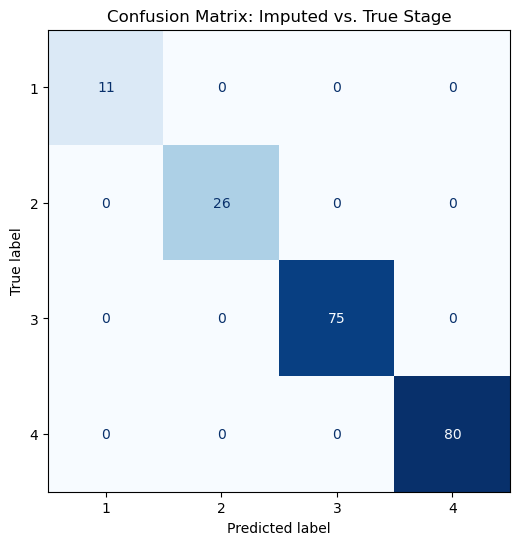

In [247]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = true.values
y_pred = stage_imp[mask_idx]

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[1,2,3,4])

# Display it
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1,2,3,4]
)
fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title("Confusion Matrix: Imputed vs. True Stage")
plt.show()


In [248]:
# df_full_imp = pd.concat([
#     X_enc, 
#     y.rename('COMBINED_STAGE_GROUP')
# ], axis=1)

# imp_full = IterativeImputer(
#     random_state=0,
#     sample_posterior=False,      
#     max_iter=10,
#     initial_strategy='most_frequent',
#     n_nearest_features=64,
#     verbose=2
# )
# X_full_completed = imp_full.fit_transform(df_full_imp)

# df_full_completed = pd.DataFrame(
#     X_full_completed,
#     index=df_full_imp.index,
#     columns=df_full_imp.columns
# )

# stage_imp = np.rint(df_full_completed['COMBINED_STAGE_GROUP']).astype(int)
# stage_imp = np.clip(stage_imp, 1, 4)

# df['COMBINED_STAGE_GROUP'] = stage_imp.values
# df.to_csv('analysis_ready_mice_all.csv', index=False)